In [1]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from datetime import date
import re
from tqdm import tqdm
import time
from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr
from scipy.spatial.distance import jaccard, euclidean, cosine
import functools
import operator

today = date.today()

**FIND DHS ENRICHMENTS**

In [4]:
columns = ['seqname', 'start', 'end', '?']
bins_25kb = pd.read_csv('../data/Altius_100k_epilogos_hg19_WM20210518.bed', delimiter='\t', names=columns)
bins_25kb

,seqname,start,end,?
0,chr1,9000,34000,0.41
1,chr1,34000,59000,0.41
2,chr1,61000,86000,0.41
3,chr1,86000,111000,0.41
4,chr1,111000,136000,0.41
...,...,...,...,...
99991,chrX,155042800,155067800,0.41
99992,chrX,155067800,155092800,0.41
99993,chrX,155092800,155117800,0.41
99994,chrX,155117800,155142800,0.41


In [5]:
dhs_metadata = pd.read_pickle('../data/dhs_metadata.pkl')
dhs_metadata

,seqname,start,end,mean_signal,numsamples,summit,core_start,core_end,component
identifier,,,,,,,,,
1.10011,chr1,16140,16200,0.129388,1,16170,16170.0,16170.0,Tissue invariant
1.10021,chr1,51868,52040,0.080034,1,51970,51970.0,51970.0,Placental / trophoblast
1.10025,chr1,57280,57354,0.273251,4,57350,57350.0,57350.0,Neural
1.10027,chr1,66370,66482,0.183716,8,66430,66410.0,66430.0,Primitive / embryonic
1.1003,chr1,79100,79231,0.113049,2,79150,79150.0,79150.0,Placental / trophoblast
...,...,...,...,...,...,...,...,...,...
Y.994281,chrY,56882540,56882719,0.038079,1,56882610,56882610.0,56882610.0,Lymphoid
Y.994286,chrY,56882864,56882980,0.115489,1,56882930,56882930.0,56882930.0,Lymphoid
Y.994292,chrY,56883733,56883960,0.491377,5,56883830,56883742.0,56883870.0,Placental / trophoblast


In [6]:
# Calculate expected values
# Number of regions:
num_regions = len(bins_25kb)
# Total number of DHSs per component:
dhs_per_comp = dhs_metadata.component.value_counts()
# Total number of DHS per component divided by Number of Regions
expected = dhs_per_comp/num_regions
expected

Primitive / embryonic      6.265661
Neural                     4.614965
Stromal B                  4.048992
Lymphoid                   2.802032
Placental / trophoblast    2.649906
Musculoskeletal            2.169027
Cancer / epithelial        1.884965
Myeloid / erythroid        1.866235
Organ devel. / renal       1.591434
Tissue invariant           1.576763
Digestive                  1.446868
Renal / cancer             1.440928
Cardiac                    1.188738
Pulmonary devel.           0.963729
Vascular / endothelial     0.848294
Stromal A                  0.561882
Name: component, dtype: float64

In [47]:
## DON'T RUN THIS

enrichment = pd.DataFrame()

# Look for all DHSs in 25kb bins
for row in bins_25kb.index:
    region_start = bins_25kb.loc[row].start
    region_end = bins_25kb.loc[row].end
    chromosome = bins_25kb.loc[row].seqname
    dhs_metadata_sub = dhs_metadata[dhs_metadata['seqname'] == chromosome]
    dhs_metadata_sub = dhs_metadata_sub.loc[(dhs_metadata_sub['start'] > region_start) & (dhs_metadata_sub['end'] < region_end)]
    component_count = dhs_metadata_sub['component'].value_counts()
    enrichment = pd.concat([enrichment, component_count.divide(expected, fill_value=0)], axis=1)
enrichment = enrichment.T
enrichment = enrichment.set_index(list(range(len(bins_25kb))))
enrichment

KeyboardInterrupt: 

In [ ]:
enrichment = np.log2(enrichment)
enrichment

In [48]:
pkl_file = pd.read_pickle('../output/dhs_enrichment_25kb.pkl')
pkl_file

[Cancer / epithelial        0.000000
 Cardiac                    0.000000
 Digestive                  0.000000
 Lymphoid                   0.000000
 Musculoskeletal            0.000000
 Myeloid / erythroid        0.000000
 Neural                     0.000000
 Organ devel. / renal       0.000000
 Placental / trophoblast    0.000000
 Primitive / embryonic      0.000000
 Pulmonary devel.           0.000000
 Renal / cancer             0.000000
 Stromal A                  0.000000
 Stromal B                  0.000000
 Tissue invariant           0.634211
 Vascular / endothelial     0.000000
 Name: component, dtype: float64,
 Cancer / epithelial        0.000000
 Cardiac                    0.000000
 Digestive                  0.000000
 Lymphoid                   0.000000
 Musculoskeletal            0.000000
 Myeloid / erythroid        0.000000
 Neural                     0.216686
 Organ devel. / renal       0.000000
 Placental / trophoblast    0.377372
 Primitive / embryonic      0.000000
 Pul

In [56]:
enrichment_df = pd.concat(pkl_file, axis=1).T
enrichment_df.index = list(range(len(pkl_file)))
enrichment_df

,Cancer / epithelial,Cardiac,Digestive,Lymphoid,Musculoskeletal,Myeloid / erythroid,Neural,Organ devel. / renal,Placental / trophoblast,Primitive / embryonic,Pulmonary devel.,Renal / cancer,Stromal A,Stromal B,Tissue invariant,Vascular / endothelial
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.000000,0.0,0.000000,0.634211,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.216686,0.000000,0.377372,0.0000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.691148,0.000000,0.000000,0.000000,0.000000,0.000000,0.754744,0.1596,0.0,0.000000,0.0,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.691148,0.356884,0.461036,0.000000,0.216686,0.000000,0.754744,0.0000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
4,0.000000,0.000000,0.691148,0.356884,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.000000,0.0,0.246975,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99991,0.530514,0.000000,0.691148,0.713768,0.922073,1.607515,0.650059,0.628364,0.000000,0.3192,0.0,5.551979,0.0,0.987900,1.268421,1.178837
99992,1.061027,1.682457,1.382296,0.713768,0.461036,2.143353,0.216686,1.256728,0.754744,0.4788,0.0,0.000000,0.0,0.493950,0.634211,2.357673
99993,1.591541,0.841229,0.691148,0.356884,0.461036,0.535838,0.216686,0.000000,0.000000,0.1596,0.0,1.387995,0.0,1.234875,1.268421,1.178837
99994,0.530514,0.000000,0.691148,0.000000,0.461036,2.143353,0.216686,0.000000,0.377372,0.6384,0.0,1.387995,0.0,0.246975,0.000000,1.178837


In [7]:
# enrichment_df.to_pickle('../data/dhs_enrichment_df_25kb.pkl')
enrichment_df = pd.read_pickle('../data/dhs_enrichment_df_25kb.pkl')

In [8]:
enrichment_df = pd.concat([bins_25kb.iloc[:, :3], enrichment_df], axis=1)
enrichment_df

,seqname,start,end,seqname,start,end,Cancer / epithelial,Cardiac,Digestive,Lymphoid,...,Neural,Organ devel. / renal,Placental / trophoblast,Primitive / embryonic,Pulmonary devel.,Renal / cancer,Stromal A,Stromal B,Tissue invariant,Vascular / endothelial
0,chr1,9000,34000,chr1,9000,34000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0000,0.0,0.000000,0.0,0.000000,0.634211,0.000000
1,chr1,34000,59000,chr1,34000,59000,0.000000,0.000000,0.000000,0.000000,...,0.216686,0.000000,0.377372,0.0000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
2,chr1,61000,86000,chr1,61000,86000,0.000000,0.000000,0.691148,0.000000,...,0.000000,0.000000,0.754744,0.1596,0.0,0.000000,0.0,0.000000,0.000000,0.000000
3,chr1,86000,111000,chr1,86000,111000,0.000000,0.000000,0.691148,0.356884,...,0.216686,0.000000,0.754744,0.0000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
4,chr1,111000,136000,chr1,111000,136000,0.000000,0.000000,0.691148,0.356884,...,0.000000,0.000000,0.000000,0.0000,0.0,0.000000,0.0,0.246975,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99991,chrX,155042800,155067800,chrX,155042800,155067800,0.530514,0.000000,0.691148,0.713768,...,0.650059,0.628364,0.000000,0.3192,0.0,5.551979,0.0,0.987900,1.268421,1.178837
99992,chrX,155067800,155092800,chrX,155067800,155092800,1.061027,1.682457,1.382296,0.713768,...,0.216686,1.256728,0.754744,0.4788,0.0,0.000000,0.0,0.493950,0.634211,2.357673
99993,chrX,155092800,155117800,chrX,155092800,155117800,1.591541,0.841229,0.691148,0.356884,...,0.216686,0.000000,0.000000,0.1596,0.0,1.387995,0.0,1.234875,1.268421,1.178837
99994,chrX,155117800,155142800,chrX,155117800,155142800,0.530514,0.000000,0.691148,0.000000,...,0.216686,0.000000,0.377372,0.6384,0.0,1.387995,0.0,0.246975,0.000000,1.178837


In [107]:
# enrichment_df.to_pickle('../data/dhs_enrichment_df_25kb.pkl')
enrichment_df = pd.read_pickle('../data/dhs_enrichment_df_25kb.pkl')
enrichment_df

,seqname,start,end,Cancer / epithelial,Cardiac,Digestive,Lymphoid,Musculoskeletal,Myeloid / erythroid,Neural,Organ devel. / renal,Placental / trophoblast,Primitive / embryonic,Pulmonary devel.,Renal / cancer,Stromal A,Stromal B,Tissue invariant,Vascular / endothelial
0,chr1,9000,34000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.000000,0.0,0.000000,0.634211,0.000000
1,chr1,34000,59000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.216686,0.000000,0.377372,0.0000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
2,chr1,61000,86000,0.000000,0.000000,0.691148,0.000000,0.000000,0.000000,0.000000,0.000000,0.754744,0.1596,0.0,0.000000,0.0,0.000000,0.000000,0.000000
3,chr1,86000,111000,0.000000,0.000000,0.691148,0.356884,0.461036,0.000000,0.216686,0.000000,0.754744,0.0000,0.0,0.000000,0.0,0.000000,0.000000,0.000000
4,chr1,111000,136000,0.000000,0.000000,0.691148,0.356884,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.000000,0.0,0.246975,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99991,chrX,155042800,155067800,0.530514,0.000000,0.691148,0.713768,0.922073,1.607515,0.650059,0.628364,0.000000,0.3192,0.0,5.551979,0.0,0.987900,1.268421,1.178837
99992,chrX,155067800,155092800,1.061027,1.682457,1.382296,0.713768,0.461036,2.143353,0.216686,1.256728,0.754744,0.4788,0.0,0.000000,0.0,0.493950,0.634211,2.357673
99993,chrX,155092800,155117800,1.591541,0.841229,0.691148,0.356884,0.461036,0.535838,0.216686,0.000000,0.000000,0.1596,0.0,1.387995,0.0,1.234875,1.268421,1.178837
99994,chrX,155117800,155142800,0.530514,0.000000,0.691148,0.000000,0.461036,2.143353,0.216686,0.000000,0.377372,0.6384,0.0,1.387995,0.0,0.246975,0.000000,1.178837


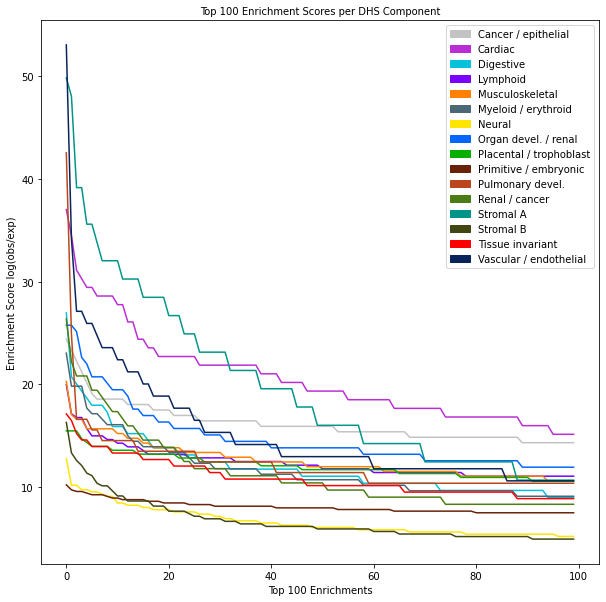

In [13]:
import matplotlib.patches as mpatches
components = enrichment_df.columns[3:].tolist()

Comp_colors = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588',
               '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16, 10, 7, 11, 2, 12, 1, 8, 4, 15, 14, 5, 9, 6, 3, 13]).astype(int) - 1
Comp_colors = np.array(Comp_colors)[neworder]

official_order_dict = {k: v for v, k in enumerate(components)}
leg_dict = {v: Comp_colors[k] for k, v in enumerate(official_order_dict)}
patchList = []
for key in leg_dict:
    data_key = mpatches.Patch(color=leg_dict[key], label=key)
    patchList.append(data_key)

plt.figure(figsize=(10, 10))
ax = plt.subplot()

ax.set_ylabel('Enrichment Score log(obs/exp)')
ax.set_xlabel('Top 100 Enrichments')
ax.set_title('Top 100 Enrichment Scores per DHS Component', fontsize=10)
plt.legend(handles=patchList)
    

for i, c in enumerate(components):
    plt.plot(list(range(100)), enrichment_df[c].sort_values(ascending=False)[:100],
                color=Comp_colors[i])
    enrichment_subset = enrichment_df.loc[enrichment_df[c].sort_values(ascending=False).index][['seqname', 'start', 'end', c]]
#     df[(df != 0).all(1)]
    enrichment_subset = enrichment_subset[(enrichment_subset!=0).all(1)]
#     print(enrichment_subset)
    if '/' in c:
        c = c.replace('/', '-')
        c = c.replace(' ', '')
    enrichment_subset.to_pickle('../output/DHS_enrichments_25kb/' + c + '_enrichments_sorted.pkl')
plt.savefig('../output/plots/ST_'+ today.strftime("%Y-%m-%d") + '_component-top100-enrichments.png')

In [10]:

# Look for all DHSs in 25kb bins
for row in bins_25kb.index:
    region_start = bins_25kb.loc[row].start
    region_end = bins_25kb.loc[row].end
    chromosome = bins_25kb.loc[row].seqname
    dhs_metadata_sub = dhs_metadata[dhs_metadata['seqname'] == chromosome]
    dhs_metadata_sub = dhs_metadata_sub.loc[(dhs_metadata_sub['start'] > region_start) & (dhs_metadata_sub['end'] < region_end)]
    component_count = dhs_metadata_sub['component'].value_counts()
    print(component_count)

Tissue invariant    1
Name: component, dtype: int64
Placental / trophoblast    1
Neural                     1
Name: component, dtype: int64
Placental / trophoblast    2
Primitive / embryonic      1
Digestive                  1
Name: component, dtype: int64
Placental / trophoblast    2
Digestive                  1
Lymphoid                   1
Neural                     1
Musculoskeletal            1
Name: component, dtype: int64
Stromal B    1
Digestive    1
Lymphoid     1
Name: component, dtype: int64
Myeloid / erythroid    1
Name: component, dtype: int64
Lymphoid                 2
Primitive / embryonic    1
Stromal B                1
Tissue invariant         1
Name: component, dtype: int64
Primitive / embryonic    3
Neural                   2
Myeloid / erythroid      1
Cancer / epithelial      1
Name: component, dtype: int64
Series([], Name: component, dtype: int64)
Series([], Name: component, dtype: int64)
Cancer / epithelial        3
Tissue invariant           1
Primitive / embryoni

In [12]:
cardiac_enrichments = pd.read_pickle('../output/DHS_enrichments_25kb/Cardiac_enrichments_sorted.pkl')
cardiac_enrichments

,seqname,start,end,Cardiac
43956,chr2,40496400,40521400,37.014057
78638,chr6,118543800,118568800,34.490372
85870,chr8,11673200,11698200,31.125457
30337,chr15,36583400,36608400,30.284229
2048,chr1,63770000,63795000,29.443000
...,...,...,...,...
6774,chr1,203911000,203936000,0.841229
34203,chr16,52268200,52293200,0.841229
6528,chr1,196397000,196422000,0.841229
17870,chr12,25474400,25499400,0.841229


In [31]:
cardiac_top10 = enrichment_df.loc[cardiac_enrichments.iloc[:10, :].index]
# print(cardiac_top10)
components = enrichment_df.columns[3:].tolist()

top_10_per_component = pd.DataFrame()

for c in components:
    if '/' in c:
        c = c.replace('/', '-')
        c = c.replace(' ', '')
    component_enrichment = pd.read_pickle('../output/DHS_enrichments_25kb/' + c + '_enrichments_sorted.pkl')

    top_10_per_component = pd.concat([top_10_per_component, enrichment_df.loc[component_enrichment.iloc[:10, :].index]], axis=0)
print(top_10_per_component)
    
cosine_dist = []
for i in range(len(top_10_per_component)):
    cosine_dist.append(cosine(top_10_per_component.iloc[i, 3:], cardiac_top10.iloc[0, 3:]))

top_10_per_component['Cosine from Cardiac1'] = cosine_dist
top_10_per_component.sort_values(by='Cosine from Cardiac1')



      seqname      start        end  Cancer / epithelial   Cardiac  Digestive  \
3437     chr1  106188000  106213000            24.403631  0.000000   0.000000   
16270   chr11  109656800  109681800            23.342604  0.841229   0.000000   
37456   chr17   61888600   61913600            22.281576  0.000000   0.691148   
52382   chr20   54922200   54947200            21.220549  0.000000   0.000000   
3196     chr1   99187000   99212000            20.159521  0.000000   0.000000   
...       ...        ...        ...                  ...       ...        ...   
75028    chr6    7871800    7896800             0.000000  0.000000   0.691148   
94866    chr9  136646200  136671200             0.000000  0.841229   1.382296   
28277   chr14   85533800   85558800             0.530514  2.523686   0.000000   
20204   chr12   96241400   96266400             0.530514  1.682457   0.691148   
84100    chr7  116520800  116545800             0.000000  4.206143   2.073444   

       Lymphoid  Musculoske

,seqname,start,end,Cancer / epithelial,Cardiac,Digestive,Lymphoid,Musculoskeletal,Myeloid / erythroid,Neural,Organ devel. / renal,Placental / trophoblast,Primitive / embryonic,Pulmonary devel.,Renal / cancer,Stromal A,Stromal B,Tissue invariant,Vascular / endothelial,Cosine from Cardiac1
43956,chr2,40496400,40521400,0.000000,37.014057,0.000000,0.000000,0.000000,1.071677,0.000000,0.000000,0.000000,0.319200,3.112910,0.693997,1.779732,1.234875,0.000000,0.000000,0.000000
78638,chr6,118543800,118568800,0.000000,34.490372,0.000000,1.427535,0.000000,0.000000,0.216686,0.000000,0.000000,0.000000,0.000000,0.693997,0.000000,1.481850,1.268421,1.178837,0.007263
30337,chr15,36583400,36608400,0.530514,30.284229,0.691148,0.356884,0.461036,0.000000,1.083432,0.628364,0.000000,0.159600,1.037637,0.693997,3.559463,1.234875,1.902632,0.000000,0.007392
2048,chr1,63770000,63795000,1.061027,29.443000,2.073444,0.713768,0.000000,0.000000,0.000000,1.256728,0.377372,2.074801,3.112910,1.387995,1.779732,1.481850,1.902632,1.178837,0.010145
52629,chr20,62548200,62573200,0.000000,28.601772,1.382296,0.000000,1.844145,2.679191,0.216686,1.256728,0.377372,1.276801,1.037637,1.387995,0.000000,0.000000,0.000000,0.000000,0.010177
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9558,chr10,42295400,42320400,1.591541,0.000000,0.691148,0.356884,0.000000,0.535838,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.234875,0.634211,53.047650,0.998938
3196,chr1,99187000,99212000,20.159521,0.000000,0.000000,1.784419,0.000000,0.000000,0.216686,0.000000,0.377372,0.478800,0.000000,0.000000,0.000000,0.493950,0.634211,0.000000,0.998989
3437,chr1,106188000,106213000,24.403631,0.000000,0.000000,0.000000,0.922073,0.000000,0.650059,0.000000,0.000000,0.638400,0.000000,0.000000,0.000000,0.246975,0.000000,0.000000,0.999441
37456,chr17,61888600,61913600,22.281576,0.000000,0.691148,1.070652,0.000000,0.000000,0.000000,0.000000,0.000000,0.159600,0.000000,0.000000,0.000000,0.000000,0.634211,1.178837,0.999939


In [36]:
closest_regions = top_10_per_component.sort_values(by='Cosine from Cardiac1')[['seqname', 'start', 'end', 'Cosine from Cardiac1']]
closest_regions_bed = BedTool.from_dataframe(closest_regions)
fn = '/home/stsai/public_html/top_cardiac_closest_regions_from_top10.bed'
closest_regions_bed.saveas(fn)
print('https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2Ftop_cardiac_closest_regions_from_top10.bed')

chr2	40496400	40521400	0.0
chr6	118543800	118568800	0.0072626354377896
chr15	36583400	36608400	0.007391742451015704
chr1	63770000	63795000	0.010145211422121436
chr20	62548200	62573200	0.01017676889010366
chr8	13493200	13518200	0.01693784289707101
chr2	46550400	46575400	0.019433087650224556
chr8	11673200	11698200	0.02167135613652793
chr4	173517200	173542200	0.02688514135714548
chr1	201356000	201381000	0.030554115798222647
chr6	138088800	138113800	0.5691462663156489
chr17	58393600	58418600	0.6913414205554989
chr15	63062400	63087400	0.7050335472922074
chr5	88655000	88680000	0.7156253143166449
chr5	151656000	151681000	0.7503080082876902
chr2	128773400	128798400	0.757716180739056
chr16	88054200	88079200	0.7627586204952456
chr2	143949400	143974400	0.7635330793732191
chr6	112068800	112093800	0.7824370202374878
chr15	63037400	63062400	0.784358316104429
chr15	96342400	96367400	0.797748765934884
chr7	116520800	116545800	0.8142277516050516
chrX	325800	350800	0.8225641478379179
chr2	28404400	28429

# CHROMATIN STATE ENRICHMENT

In [14]:
# READ IN THE BINS Alex and Jacob have been working on
chromatin_state_data = pd.read_pickle('../data/epilogos_state_data_18.pkl')
chromatin_state_data

,seqname,start,end,0,1,2,3,4,5,6,...,823,824,825,826,827,828,829,830,831,832
0,chr1,0,200,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
1,chr1,200,400,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
2,chr1,400,600,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
3,chr1,600,800,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
4,chr1,800,1000,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15181503,chrX,155269400,155269600,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
15181504,chrX,155269600,155269800,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
15181505,chrX,155269800,155270000,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
15181506,chrX,155270000,155270200,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18


In [15]:
chromatin_state_metadata = pd.read_csv('../data/All_833_biosamples/metadata.tsv', delimiter='\t')
chromatin_state_metadata

,zero_index,one_index,short_name,long_name,hex,rgba,color
0,0,1,TssA,Active TSS,#ff0000,"rgba(255,0,0,1)",Red
1,1,2,TssFlnk,Flanking TSS,#ff4500,"rgba(255,69,0,1)",Orange Red
2,2,3,TssFlnkU,Flanking TSS Upstream,#ff4500,"rgba(255,69,0,1)",Orange Red
3,3,4,TssFlnkD,Flanking TSS Downstream,#ff4500,"rgba(255,69,0,1)",Orange Red
4,4,5,Tx,Strong transcription,#008000,"rgba(0,128,0,1)",Green
5,5,6,TxWk,Weak transcription,#006400,"rgba(0,100,0,1)",DarkGreen
6,6,7,EnhG1,Genic Enhancer 1,#c2e105,"rgba(194,225,5,1)",GreenYellow
7,7,8,EnhG2,Genic Enhancer 2,#c2e105,"rgba(194,225,5,1)",GreenYellow
8,8,9,EnhA1,Active Enhancer 1,#ffc34d,"rgba(255,195,77,1)",Orange
9,9,10,EnhA2,Active Enhancer 2,#ffc34d,"rgba(255,195,77,1)",Orange


In [45]:
# Get enrichment of each chromatin state (create vector of 18 values)
# expected = Count number of state out of entire genome and divide by number of regions

# 123 columns = number of 200 bp bins in 25kb

# Row of 100k 25kb regions
rows = [0, 5, 50, 100, 200, 400]


num_per_state_per_25kb = pd.DataFrame()


for row in tqdm(range(0, len(bins_25kb), 100)):
    region_start = bins_25kb.loc[row].start
    region_end = bins_25kb.loc[row].end
    chromosome = bins_25kb.loc[row].seqname
    chromatin_state_sub = chromatin_state_data[chromatin_state_data['seqname'] == chromosome]
    chromatin_state_sub = chromatin_state_sub.loc[(chromatin_state_sub['start'] > region_start) & (chromatin_state_sub['end'] < region_end)]
#     print(chromatin_state_sub.iloc[:, 3:].T)
#     print(chromatin_state_sub.iloc[:, 3:].T.apply(pd.Series.value_counts, axis=0).sum(axis=1))
    num_per_state_per_25kb[row] = chromatin_state_sub.iloc[:, 3:].T.apply(pd.Series.value_counts, axis=0).sum(axis=1)
print(num_per_state_per_25kb)

# expected = chromatin_state_data.iloc[:, 3:13].T.apply(pd.Series.value_counts)
# print(expected)

 10%|█████████████████████                                                                                                                                                                                             | 100/1000 [12:36<1:09:54,  4.66s/it]/tmp/ipykernel_193472/994641331.py:21: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead.  To get a de-fragmented frame, use `newframe = frame.copy()`
  num_per_state_per_25kb[row] = chromatin_state_sub.iloc[:, 3:].T.apply(pd.Series.value_counts, axis=0).sum(axis=1)
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [1:28:29<00:00,  5.31s/it]

       0        100      200      300      400      500      600      700    \
2       16.0      5.0      3.0    927.0      7.0      NaN      4.0    236.0   
4        3.0     11.0      NaN   1159.0      9.0      3.0      5.0    261.0   
5        3.0      NaN      NaN      2.0      NaN      NaN      NaN     64.0   
6      805.0   2782.0    224.0  19810.0   4375.0    254.0    702.0   4839.0   
7        2.0      NaN      NaN      NaN     13.0      NaN      5.0     70.0   
10       5.0   2005.0     74.0   1175.0   1721.0     22.0    127.0    944.0   
11       6.0   1690.0    103.0   7381.0   2814.0    206.0   1300.0   2274.0   
12      22.0  14914.0   3623.0      2.0     33.0    718.0     66.0     62.0   
13      54.0  16310.0  14028.0      NaN     76.0  12844.0    452.0    278.0   
14      13.0      4.0      2.0      NaN      NaN      NaN      NaN   1814.0   
16       1.0   4302.0   2775.0      2.0   8856.0    437.0   4832.0   4035.0   
17       4.0  25163.0  29799.0    739.0  38378.0  10

In [46]:
expected = num_per_state_per_25kb.T.sum(axis=0) / 1000
expected

2       267.040
4       158.435
5      2456.560
6      8463.587
7       162.403
10      704.425
11     1130.842
12      940.777
13     3630.940
14      275.738
16     1273.281
17     4602.796
18    76307.690
dtype: float64

In [50]:
num_per_state_per_25kb_every100 = num_per_state_per_25kb.T
num_per_state_per_25kb_every100

,2,4,5,6,7,10,11,12,13,14,16,17,18
0,16.0,3.0,3.0,805.0,2.0,5.0,6.0,22.0,54.0,13.0,1.0,4.0,101525.0
100,5.0,11.0,NaN,2782.0,NaN,2005.0,1690.0,14914.0,16310.0,4.0,4302.0,25163.0,32994.0
200,3.0,NaN,NaN,224.0,NaN,74.0,103.0,3623.0,14028.0,2.0,2775.0,29799.0,51774.0
300,927.0,1159.0,2.0,19810.0,NaN,1175.0,7381.0,2.0,NaN,NaN,2.0,739.0,55900.0
400,7.0,9.0,NaN,4375.0,13.0,1721.0,2814.0,33.0,76.0,NaN,8856.0,38378.0,43171.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99500,3590.0,370.0,NaN,786.0,NaN,185.0,233.0,87.0,1041.0,39.0,20.0,1358.0,92339.0
99600,2.0,2.0,NaN,185.0,NaN,88.0,234.0,529.0,2683.0,NaN,NaN,348.0,98324.0
99700,2.0,NaN,NaN,1.0,NaN,NaN,NaN,592.0,9724.0,NaN,13.0,269.0,91858.0
99800,3.0,1.0,NaN,NaN,NaN,NaN,5.0,61.0,540.0,NaN,121.0,1915.0,99813.0


In [51]:
obs_over_exp = num_per_state_per_25kb_every100.divide(expected)
obs_over_exp

,2,4,5,6,7,10,11,12,13,14,16,17,18
0,0.059916,0.018935,0.001221,0.095113,0.012315,0.007098,0.005306,0.023385,0.014872,0.047146,0.000785,0.000869,1.330469
100,0.018724,0.069429,NaN,0.328702,NaN,2.846293,1.494462,15.852854,4.491950,0.014507,3.378673,5.466894,0.432381
200,0.011234,NaN,NaN,0.026466,NaN,0.105050,0.091083,3.851072,3.863462,0.007253,2.179409,6.474108,0.678490
300,3.471390,7.315303,0.000814,2.340615,NaN,1.668027,6.526995,0.002126,NaN,NaN,0.001571,0.160555,0.732561
400,0.026213,0.056806,NaN,0.516920,0.080048,2.443127,2.488411,0.035077,0.020931,NaN,6.955260,8.337975,0.565749
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99500,13.443679,2.335343,NaN,0.092868,NaN,0.262626,0.206041,0.092477,0.286703,0.141439,0.015707,0.295038,1.210088
99600,0.007490,0.012623,NaN,0.021858,NaN,0.124925,0.206925,0.562301,0.738927,NaN,NaN,0.075606,1.288520
99700,0.007490,NaN,NaN,0.000118,NaN,NaN,NaN,0.629267,2.678094,NaN,0.010210,0.058443,1.203784
99800,0.011234,0.006312,NaN,NaN,NaN,NaN,0.004421,0.064840,0.148722,NaN,0.095030,0.416051,1.308033


In [69]:
chromatin_state_enrichment = np.log2(obs_over_exp).fillna(0)
chromatin_state_enrichment.to_pickle('../output/chromatin_state_enrichment_25kb_every100bin.pkl')
chromatin_state_enrichment

,2,4,5,6,7,10,11,12,13,14,16,17,18
0,-4.060912,-5.722785,-9.677461,-3.394209,-6.343434,-7.138374,-7.558219,-5.418277,-6.071240,-4.406715,-10.314335,-10.168295,0.411935
100,-5.738984,-3.848316,0.000000,-1.605147,0.000000,1.509084,0.579626,3.986671,2.167342,-6.107154,1.756457,2.450722,-1.209625
200,-6.475950,0.000000,0.000000,-5.239699,0.000000,-3.250849,-3.456681,1.945260,1.949894,-7.107154,1.123937,2.694682,-0.559601
300,1.795513,2.870918,-10.262424,1.226888,0.000000,0.738143,2.706419,-8.877709,0.000000,0.000000,-9.314335,-2.638864,-0.448980
400,-5.253557,-4.137822,0.000000,-0.951986,-3.642995,1.288729,1.315225,-4.833315,-5.578200,0.000000,2.798104,3.059697,-0.821766
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99500,3.748856,1.223634,0.000000,-3.428668,0.000000,-1.928921,-2.278996,-3.434765,-1.802373,-2.821752,-5.992407,-1.761027,0.275112
99600,-7.060912,-6.307747,0.000000,-5.515672,0.000000,-3.000871,-2.272817,-0.830585,-0.436496,0.000000,0.000000,-3.725351,0.365715
99700,-7.060912,0.000000,0.000000,-13.047054,0.000000,0.000000,0.000000,-0.668256,1.421207,0.000000,-6.613895,-4.096832,0.267577
99800,-6.475950,-7.307747,0.000000,0.000000,0.000000,0.000000,-7.821254,-3.946972,-2.749312,0.000000,-3.395472,-1.265166,0.387399


In [106]:
state7_top1 = chromatin_state_enrichment[7].sort_values(ascending=False).index[0]
# print(state7_top1)

states = chromatin_state_enrichment.columns

top_10_per_state_indices = pd.DataFrame()

for s in states:
    state_enrichment = chromatin_state_enrichment[s]
#     print(state_enrichment.index)
    top_10_per_state_indices[s] = state_enrichment.sort_values(ascending=False)[:10].index
# print(top_10_per_state_indices)

print(chromatin_state_enrichment.loc[top_10_per_state_indices.loc[7]].iloc[7])
    
cosine_dist = []
for i in states:
    for top in 10:
        print(i, top)
        cosine_dist.append(cosine(chromatin_state_enrichment.loc[top_10_per_state_indices.iloc[i]], state7_top1))

# top_10_per_state['Cosine from State7'] = cosine_dist
# top_10_per_state.sort_values(by='Cosine from State7')


2    -5.738984
4    -3.848316
5     0.000000
6    -1.605147
7     0.000000
10    1.509084
11    0.579626
12    3.986671
13    2.167342
14   -6.107154
16    1.756457
17    2.450722
18   -1.209625
Name: 100, dtype: float64


TypeError: 'int' object is not iterable

##### 

In [6]:
bins_200 = chromatin_state_data.iloc[:, :3]
bins_200

,seqname,start,end
0,chr1,0,200
1,chr1,200,400
2,chr1,400,600
3,chr1,600,800
4,chr1,800,1000
...,...,...,...
15181503,chrX,155269400,155269600
15181504,chrX,155269600,155269800
15181505,chrX,155269800,155270000
15181506,chrX,155270000,155270200


Consider weighing those with a greater number of DHSs differently than those with just 1 DHS.

In [ ]:
hg38_25kb_ranges = {}

for chrm in chromosomes.keys():
    chrm_genes = hg19_proc_gene_df[hg19_proc_gene_df['chr'] == chrm].sort_values(by='start')
    start = 0
    chrm_dict = {}
    for i in range(1, len(chrm_genes)):
        gene1 = chrm_genes.iloc[i-1, :]
        gene2 = chrm_genes.iloc[i, :]

        diff = (gene2.start - gene1.end)//2
        chrm_dict[(start, gene1.end+diff)] = gene1.name
        start = gene2.start - diff
    
    chrm_dict[(start, chromosomes[chrm])] = gene2.name
    hg19_gene_ranges[chrm] = chrm_dict

    
hg38_gene_ranges = {}